1. [1.5p] Carga los datos y desarrolla código que indique:

a.       Número de viviendas en los datos.

b.      Número total de variables.

c.       Las cinco variables con mayor número de valores nulos.

d.      Porcentaje de valores nulos de cada una de ellas.

Explica brevemente qué problema pueden causar los valores nulos en un modelo de aprendizaje automático.

In [47]:
#Importamos todas las librerias necesarias

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Para que se vean todas las columnas
pd.set_option('display.max_columns', None)

In [57]:
df = pd.read_csv('data.csv')

#Apartado a

num_viviendas = df.shape[0]
print(f"\nNúmero total de viviendas:", num_viviendas)

# Apartado b

num_variables = df.shape[1]
print(f"\nNumero de variables: ", num_variables)

# Apartado c

missing_series = df.isnull().sum()
missing_vars = missing_series[missing_series > 0].sort_values(ascending=False).head(5)

print("\nVariables con mayor número de valores nulos:\n", missing_vars)

#Apartado d sabiendo que las columnas con mayor cantidad de nulos son PoolQC, MiscFeature, Alley, Fence y MasVnrType las añadimos a la lista para recorrerlas

variables_estudio = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']

resumen_porcentajes = []

for col in variables_estudio:
    n_nulos = df[col].isnull().sum()
    porcentajes = (n_nulos/df.shape[0]) * 100
    
    resumen_porcentajes.append({
        'Variable': col,
        'Nulos': n_nulos,
        'Porcentajes' : porcentajes
    })

df_resumen = pd.DataFrame(resumen_porcentajes)
df_resumen


Número total de viviendas: 1460

Numero de variables:  81

Variables con mayor número de valores nulos:
 PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
dtype: int64


,Variable,Nulos,Porcentajes
0,PoolQC,1453,99.520548
1,MiscFeature,1406,96.301370
2,Alley,1369,93.767123
3,Fence,1179,80.753425
4,MasVnrType,872,59.726027


El problema viene dado de que en cada columna un valor nulo puede significar cosas distintas (como en este caso), por ejemplo en Fence puede significar que no tiene valla mientras que en otras variables simplemente puede significar que no se ha recogido ningún valor para esa variable causando problemas a la hora de diferenciar cuando significa cada cosa.

2.      [3p] Realiza un análisis exploratorio de la variable KitchenQual. Indica:

a.       Tipo de variable.

b.      Valores posibles.

c.       Existencia de valores nulos.

d.      Distribución de frecuencias.

e.       Método de preprocesamiento que aplicarías antes de utilizarla en un modelo.

Justifica todas las decisiones tomadas.

In [49]:
# Apartado a

tipo = df['KitchenQual'].dtypes

print("\nEl tipo de la variable es: ", tipo)

# Apartado b

valores = df['KitchenQual'].unique()

print("\nPuede tomar los valores: ", valores)

# Apartado c

nulos = df['KitchenQual'].isnull().sum()

print("\nSu cantidad de nulos es: ", nulos)

# Apartado d

df['KitchenQual'] = df['KitchenQual'].map({'Gd': 1,'TA': 2, 'Ex': 3, 'Fa': 4})

print("\nLa frecuencia de cada valor es:", df['KitchenQual'].value_counts())




El tipo de la variable es:  object

Puede tomar los valores:  ['Gd' 'TA' 'Ex' 'Fa']

Su cantidad de nulos es:  0

La frecuencia de cada valor es: KitchenQual
2    735
1    586
3    100
4     39
Name: count, dtype: int64


e. En esta columna al no haber nulos no tendremos problema teniendo que sustituirlos por otro valor, únicamente hemos mapeado cada valor que pudiera tener la variable a unos numéricos para poder contar cuantos había de cada tipo siendo 1 Gd, 2 TA, 3 Ex y 4 Fa.

3.      [2.5p] Analiza conjuntamente las variables GrLivArea y SalePrice:

a.       Muestra histogramas de ambas variables.

b.      Detecta posibles outliers.

c.       Calcula la correlación entre ellas.

d.      Indica si consideras conveniente realizar alguna transformación adicional.

Text(0, 0.5, 'Frecuencia')

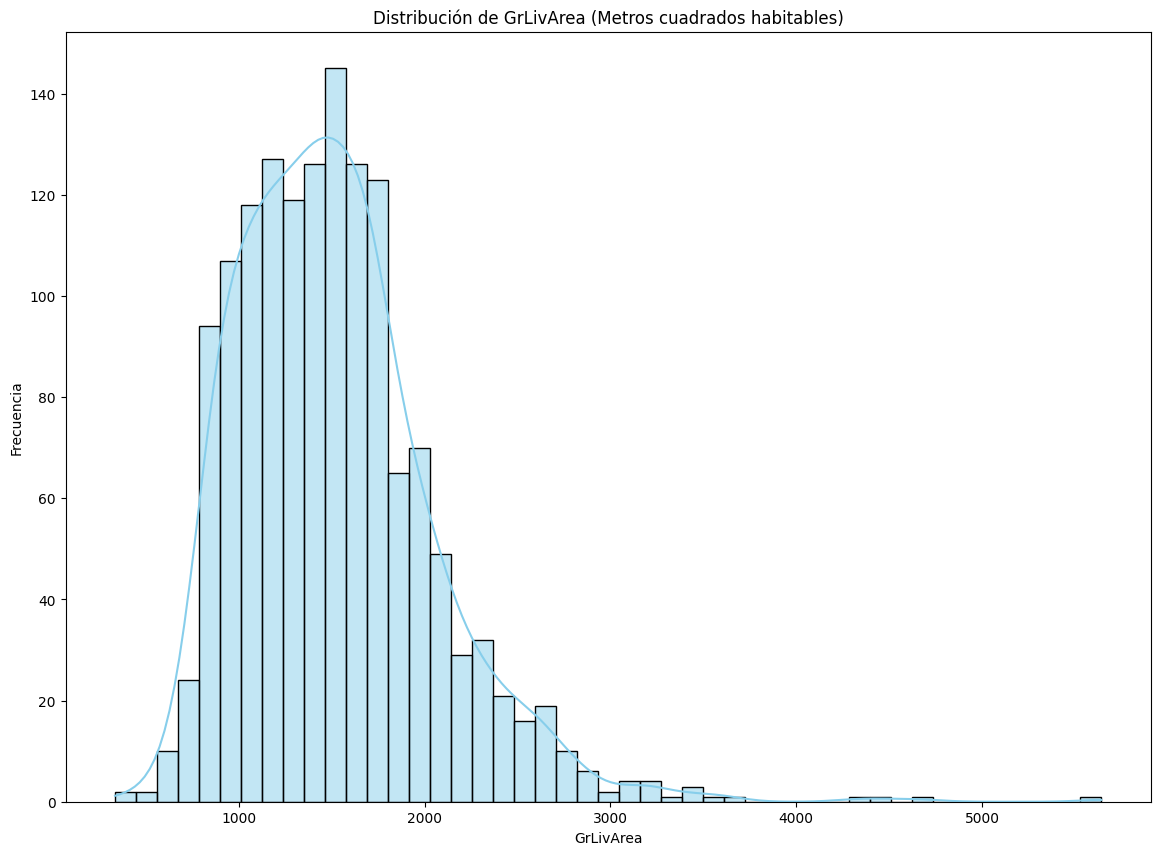

In [50]:
#Apartado a

fig, axes = plt.subplots(figsize=(14, 10))

sns.histplot(df['GrLivArea'], kde=True, ax=axes, color='skyblue')
axes.set_title('Distribución de GrLivArea (Metros cuadrados habitables)')
axes.set_xlabel('GrLivArea')
axes.set_ylabel('Frecuencia')

Text(0, 0.5, 'Frecuencia')

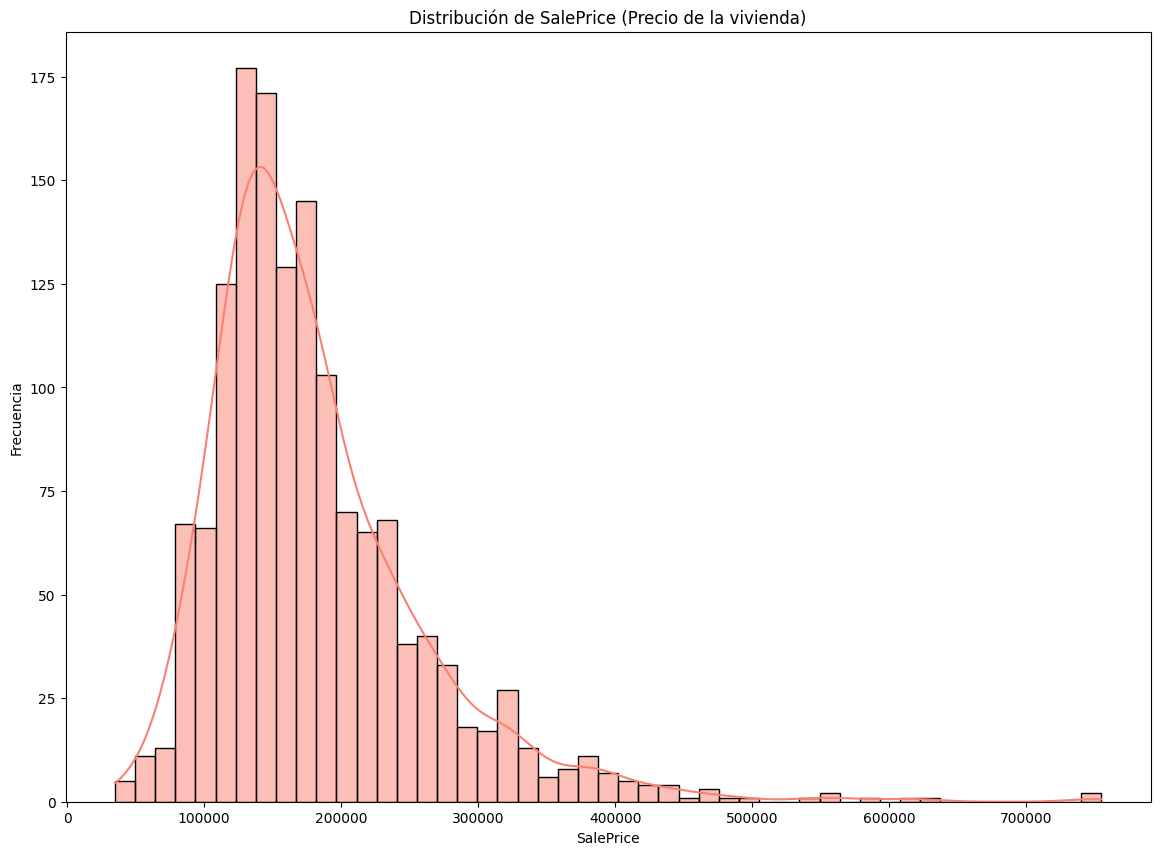

In [51]:
fig, axes = plt.subplots(figsize=(14, 10))

sns.histplot(df['SalePrice'], kde=True, ax=axes, color='salmon')
axes.set_title('Distribución de SalePrice (Precio de la vivienda)')
axes.set_xlabel('SalePrice')
axes.set_ylabel('Frecuencia')

En el caso del histograma de GrLivArea los posibles valores outliers serían aquellos a partir de 3000/3500 siendo estos valores mayores que la  mediana y que la media. En el caso de SalePrice los outliers serían aquellos valores a partir de 450.000$ puesto que ya son valores atípicos que están alejados igual que en otro histograma de su media y mediana pudiendo distorsionar así los resultados de ambas medias.

In [52]:
correlacion = df['GrLivArea'].corr(df['SalePrice'])

print("La correlacion entre ambas variables es de: ", correlacion)

La correlacion entre ambas variables es de:  0.7086244776126521


d. En caso de que se fuera a usar la media sería correcto eliminar aquellos valores outliers puesto que no son lo más normal y lo único que va a hacer va a ser dispararla siendo una media "artificial" por no ser tan real y fiel a los datos.

4.      [3p] Considera las variables GarageCars, GarageArea y SalePrice:

a.       Calcula la matriz de correlación.

b.      Representa la matriz gráficamente.

c.       Determina cuál de las dos primeras variables parece más relacionada con SalePrice.

d.      Si tuvieras que eliminar una de las variables GarageCars o GarageArea por redundancia, ¿cuál elegirías y por qué?

            GarageCars  GarageArea  SalePrice
GarageCars    1.000000    0.882475   0.640409
GarageArea    0.882475    1.000000   0.623431
SalePrice     0.640409    0.623431   1.000000


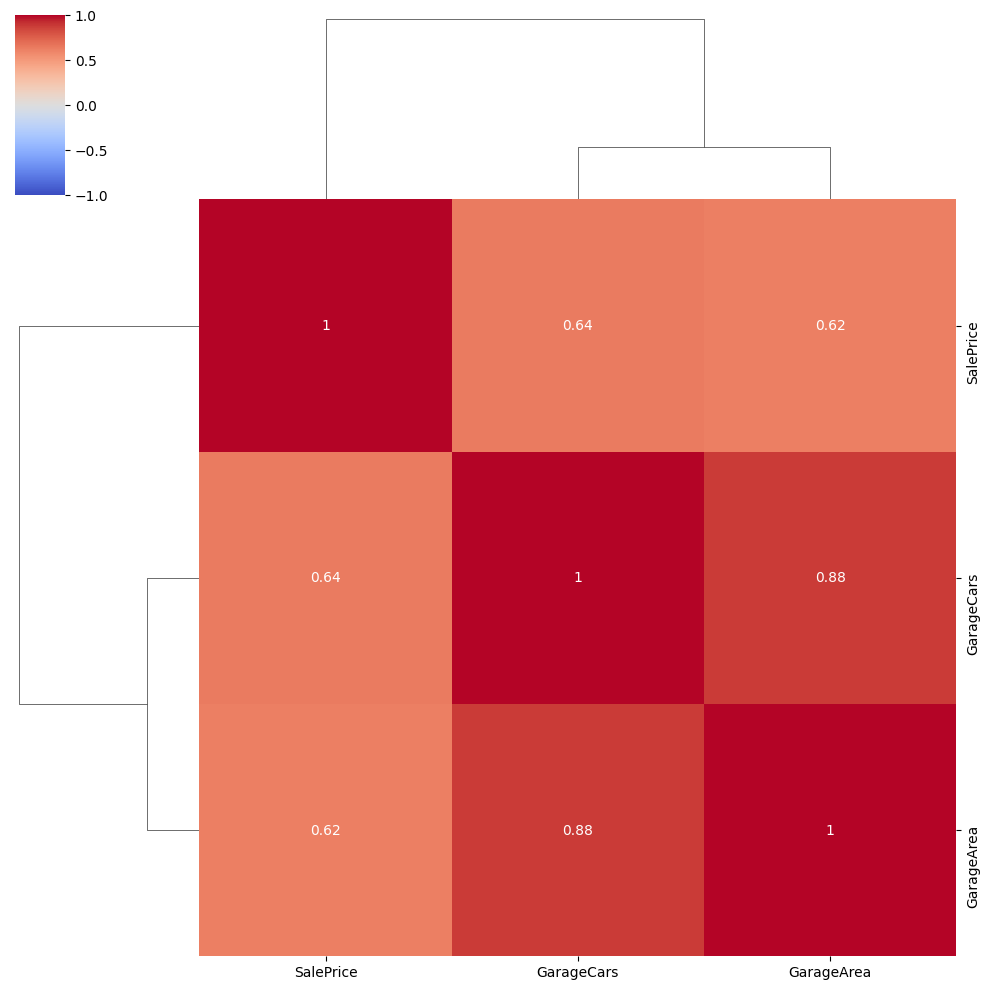

In [55]:
#Apartado a

cols = ['GarageCars', 'GarageArea', 'SalePrice']
matriz_corr = df[cols].corr()
print(matriz_corr)

#Apartado b
sns.clustermap(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1, figsize=(10, 10), annot=True)
plt.show()


c. Como podemos ver GarageCars está más correlacionado con SalePrice que GarageArea, esto nos lo demuestra tanto el valor de la correlación como su representación gráfica.

d. En caso de eliminar una de las 2 columnas eliminaría GarageArea puesto que es la que menor correlación tiene con SalePrice. No supondría ninguna falla en el diseño puesto que GarageCars y GarageArea están muy correlacionadas también entre sí (a mayor área de garaje mayor cantidad de coches entran en él) por lo que se seguiría teniendo la "misma" información. 